# Taiwanese Bankruptcy Prediction

Can a firm's financial ratios tell us, ahead of time, that it is heading for bankruptcy? This notebook combines **variable selection** with a **decision-tree classifier** to support that decision.

**Data.** Taiwan Economic Journal, 1999–2009, distributed by the UCI Machine Learning Repository: *Taiwanese Bankruptcy Prediction*, DOI [10.24432/C5004D](https://doi.org/10.24432/C5004D). Original study: Liang et al. (2016), *European Journal of Operational Research*, 252(2).

**Outline.**
1. Problem Formulation & EDA
2. Variable Selection
3. Model Selection and Decision Tree Tuning
4. Evaluation of the Final Model

## 0. Setup

In [1]:
# Import the libraries used throughout the notebook
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
from matplotlib.patches import Patch
plt.style.use("default")
plt.style.use("ggplot")

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, FixedThresholdClassifier, cross_val_score
from sklearn.metrics import roc_auc_score, make_scorer, recall_score, precision_score, accuracy_score, ConfusionMatrixDisplay
from sklearn.preprocessing import QuantileTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.feature_selection import SelectFromModel
from sklearn.utils import resample
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier

**Model selection & validation** (`model_selection`)

- `train_test_split`: splits data into train and test sets.
- `StratifiedKFold`: cross-validation splitter that preserves class proportions in each fold.
- `GridSearchCV`: exhaustive hyperparameter search with cross-validation.
- `FixedThresholdClassifier`: wraps a classifier to predict using a fixed decision threshold (e.g. 0.3) instead of the default 0.5.
- `cross_val_score`: returns the cross-validated score of a model.

**Metrics** (`metrics`)

- `roc_auc_score`: area under the ROC curve (ranking quality across all thresholds).
- `make_scorer`: turns a metric function into a scorer usable by `GridSearchCV` / `cross_val_score`.
- `recall_score`: share of actual positives that are found.
- `precision_score`: share of predicted positives that are correct.
- `accuracy_score`: share of all predictions that are correct.
- `ConfusionMatrixDisplay`: plots a confusion matrix.

**Preprocessing**

- `QuantileTransformer`: maps features to a uniform or normal distribution based on their quantiles (robust to outliers and skew).

**Models**

- `LogisticRegression`: linear classifier that outputs probabilities.
- `DecisionTreeClassifier`: tree-based classifier built from successive splits.
- `RandomForestClassifier`: many decision trees whose votes are averaged (used only as a benchmark in 3.6).
- `DummyClassifier`: trivial baseline (e.g. always predicts the majority class) to compare real models against.

**Pipelines & feature selection**

- `make_pipeline` / `Pipeline`: chain preprocessing and model steps into one estimator (avoids data leakage in CV). `make_pipeline` auto-names the steps.
- `SelectFromModel`: keeps only features that a fitted model considers important (e.g. non-zero coefficients with L1 logistic regression).

**Utilities & visualization**

- `resample`: bootstraps or subsamples data (e.g. to oversample or undersample a class, or compute bootstrap confidence intervals).
- `plot_tree`: draws a fitted decision tree.

In [2]:
# Check the scikit-learn version: the LASSO of Step 2 relies on l1_ratio=1 meaning an L1 penalty, which holds from scikit-learn 1.8
import sklearn
assert tuple(map(int, sklearn.__version__.split(".")[:2])) >= (1, 8), "scikit-learn >= 1.8 is required (see requirements.txt)"

In [3]:
# Define the global constants: random seed and loss table of the decision problem (see 1.1)
SEED = 42
C_FN, C_FP = 10, 1                  # cost of missing a bankruptcy, cost of a false alarm
THRESHOLD = C_FP / (C_FP + C_FN)    # flag a firm when P(bankrupt | x) >= 1/11

## 1. Problem Formulation & EDA

### 1.1 Problem formulation

- **Target.** `Bankrupt?`, denoted $Y$: $Y = 1$ if the firm went bankrupt under the Taiwan Stock Exchange rules, $Y = 0$ otherwise.
- **Inputs.** 95 financial ratios describing each firm, denoted $x$.
- **Decision supported.** A credit analyst decides whether to **flag** a firm as high-risk (deny or reprice credit, open a closer review) or **not flag** it.

| | Healthy ($Y = 0$) | Bankrupt ($Y = 1$) |
|---|---|---|
| **Not flag** ($a = 0$) | $0$ | $C_{FN} = 10$ |
| **Flag** ($a = 1$) | $C_{FP} = 1$ | $0$ |

**Decision rule.** With $p = P(Y = 1 \mid x)$, flagging costs $C_{FP}\,(1 - p)$ in expectation and not flagging costs $C_{FN}\,p$. Flagging is therefore optimal when

$$p \;\geq\; \frac{C_{FP}}{C_{FP} + C_{FN}} = \frac{1}{11} \approx 0.09.$$

**Metric.** Average misclassification cost per firm, where lower is better, complemented by recall and precision:

$$\text{Cost} = \frac{C_{FN} \cdot \text{FN} + C_{FP} \cdot \text{FP}}{n}.$$

Accuracy is not used because the classes are highly imbalanced (see 1.2).

**Baseline.** "Never flag", i.e. always predict the majority class.

> **Assumption:** the costs $C_{FN} = 10$ and $C_{FP} = 1$ are stipulated, not estimated: missing a bankruptcy (credit loss) is taken as ten times worse than a false alarm (unnecessary review). Step 4 checks the sensitivity of the results to cost ratios of 5 and 20.

> **Assumption:** the ratios are known before the bankruptcy outcome (no leakage), and each row is treated as an independent observation from one population. The data has no firm identifier and no year, so we cannot check whether a firm appears in several years, and neither a time-based nor a firm-based split is possible; these limitations are discussed in Step 4.

### 1.2 Data loading and integrity checks

In [4]:
# Load the dataset and strip the leading spaces from the column names
df = pd.read_csv("../data/data.csv")
df.columns = df.columns.str.strip()

In [5]:
# Display the dataset dimensions and its first rows
print(df.shape)
df.head()

(6819, 96)


,Bankrupt?,ROA(C) before interest and depreciation before interest,ROA(A) before interest and % after tax,ROA(B) before interest and depreciation after tax,Operating Gross Margin,Realized Sales Gross Margin,Operating Profit Rate,Pre-tax net Interest Rate,After-tax net Interest Rate,Non-industry income and expenditure/revenue,...,Net Income to Total Assets,Total assets to GNP price,No-credit Interval,Gross Profit to Sales,Net Income to Stockholder's Equity,Liability to Equity,Degree of Financial Leverage (DFL),Interest Coverage Ratio (Interest expense to EBIT),Net Income Flag,Equity to Liability
0,1,0.370594,0.424389,0.405750,0.601457,0.601457,0.998969,0.796887,0.808809,0.302646,...,0.716845,0.009219,0.622879,0.601453,0.827890,0.290202,0.026601,0.564050,1,0.016469
1,1,0.464291,0.538214,0.516730,0.610235,0.610235,0.998946,0.797380,0.809301,0.303556,...,0.795297,0.008323,0.623652,0.610237,0.839969,0.283846,0.264577,0.570175,1,0.020794
2,1,0.426071,0.499019,0.472295,0.601450,0.601364,0.998857,0.796403,0.808388,0.302035,...,0.774670,0.040003,0.623841,0.601449,0.836774,0.290189,0.026555,0.563706,1,0.016474
3,1,0.399844,0.451265,0.457733,0.583541,0.583541,0.998700,0.796967,0.808966,0.303350,...,0.739555,0.003252,0.622929,0.583538,0.834697,0.281721,0.026697,0.564663,1,0.023982
4,1,0.465022,0.538432,0.522298,0.598783,0.598783,0.998973,0.797366,0.809304,0.303475,...,0.795016,0.003878,0.623521,0.598782,0.839973,0.278514,0.024752,0.575617,1,0.035490


In [6]:
# Check for missing values and duplicated rows
print("Missing values:", df.isna().sum().sum(), "| Duplicated rows:", df.duplicated().sum())

Missing values: 0 | Duplicated rows: 0


**Observation:** no missing values and no duplicated rows, so no imputation or deduplication is needed.

In [7]:
# Count the firms in each class and their proportions
pd.concat([df["Bankrupt?"].value_counts(), df["Bankrupt?"].value_counts(normalize=True).round(3)], axis=1)

,count,proportion
Bankrupt?,,
0,6599,0.968
1,220,0.032


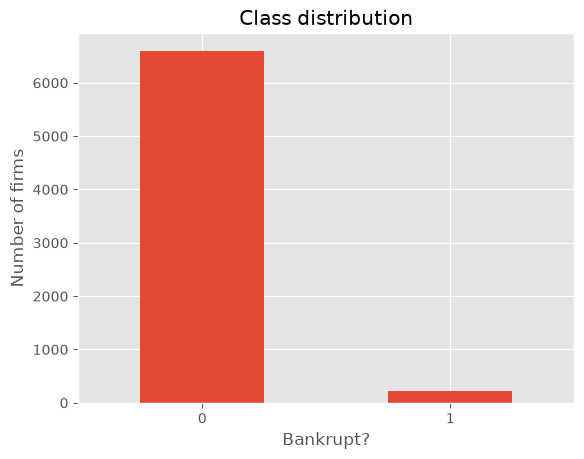

In [8]:
# Plot the class distribution of the target
df["Bankrupt?"].value_counts().plot.bar(title="Class distribution", xlabel="Bankrupt?", ylabel="Number of firms", rot=0);

**Observation:** only 220 of 6,819 firms (3.2%) went bankrupt. "Never flag" would reach 96.8% accuracy while catching no bankruptcy, at an average cost of $10 \times 0.032 \approx 0.32$ per firm: this is the reference every model must beat.

In [9]:
# Identify the columns that take a single value
constant_cols = df.columns[df.nunique() == 1].tolist()
constant_cols

['Net Income Flag']

> **Decision:** drop `Net Income Flag`. It takes the same value for every firm, so it carries no information.

In [10]:
# Drop the constant columns
df = df.drop(columns=constant_cols)

In [11]:
# Separate the features from the target
X, y = df.drop(columns="Bankrupt?"), df["Bankrupt?"]

### 1.3 Exploratory analysis

> **Decision:** the exploratory analysis uses the full dataset. It is descriptive only: no model, threshold or transformation is fitted here, and every data-driven choice of Steps 2–3 is made on the training set.

In [12]:
# Summarise, for each feature, the values above 1 (count and range)
X[X > 1].agg(["count", "min", "max"]).T.query("count > 0").sort_values("count")

,count,min,max
Current Ratio,1.0,2.750000e+09,2.750000e+09
Fixed Assets to Assets,1.0,8.320000e+09,8.320000e+09
Revenue per person,2.0,7.050000e+09,8.810000e+09
Net Value Growth Rate,2.0,1.350000e+09,9.330000e+09
Quick Assets/Current Liability,3.0,7.540000e+09,8.820000e+09
Revenue Per Share (Yuan ¥),5.0,1.510000e+09,3.020000e+09
Total debt/Total net worth,8.0,4.740000e+08,9.940000e+09
Quick Ratio,9.0,2.990000e+09,9.230000e+09
Allocation rate per person,12.0,2.320000e+07,9.570000e+09
Average Collection Days,18.0,1.370000e+08,9.730000e+09


**Observation:** 24 features mix values in $[0, 1]$ with values between $6 \times 10^5$ and $10^{10}$, with nothing in between. For some features this concerns a handful of firms, for others most of them (`Total Asset Growth Rate`: 6,017 firms). These values look like an encoding artifact rather than real ratios.

> **Decision:** keep the raw values. A decision tree only uses the order of the values, so it is unaffected; the treatment required by a linear selector is decided in Step 2.

> **Decision:** measure correlation with Spearman's rank correlation rather than Pearson's. It captures any monotone relationship, such as a ratio and its inverse (`Current Ratio` and `Current Liability to Current Assets`), and it is insensitive to the extreme values found above. It also matches the decision tree, which only uses the order of the values.

In [13]:
# Compute the Spearman rank correlation matrix of the features
corr = X.corr(method="spearman")

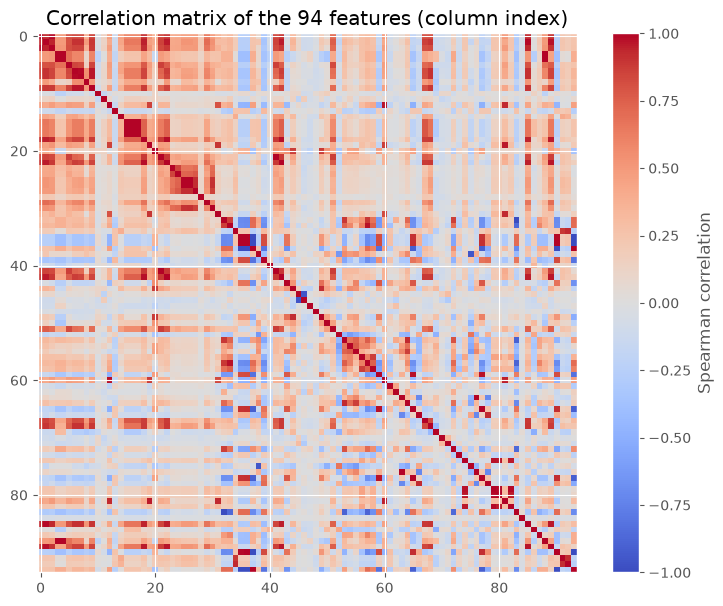

In [14]:
# Plot the correlation matrix of the features, in dataset column order
plt.figure(figsize=(9, 7))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Spearman correlation")
plt.title("Correlation matrix of the 94 features (column index)");

**Observation:** the matrix shows blocks of strongly related features: profitability (indices 0–9: ROA, margins, interest rates), per-share values (15–22: net value per share, EPS), profit growth rates (23–27), leverage (35–39, in blue where one ratio is the inverse of another) and cash-flow ratios (79–82).

In [15]:
# List the feature pairs with an absolute correlation above 0.95
pairs = corr.abs().where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
pairs[pairs > 0.95].sort_values(ascending=False)

Current Liabilities/Equity                               Current Liability to Equity                          1.000000
Current Liabilities/Liability                            Current Liability to Liability                       1.000000
Debt ratio %                                             Net worth/Assets                                     1.000000
Net worth/Assets                                         Equity to Liability                                  1.000000
Debt ratio %                                             Equity to Liability                                  1.000000
Operating Gross Margin                                   Gross Profit to Sales                                1.000000
Net Value Per Share (B)                                  Net Value Per Share (A)                              0.999948
Operating Profit Per Share (Yuan ¥)                      Operating profit/Paid-in capital                     0.999484
Net Value Per Share (A)                         

**Observation:** 50 feature pairs have $|\rho| > 0.95$, involving 47 of the 94 features, and 13 of them are practically identical ($|\rho| > 0.999$), e.g. `Debt ratio %` and `Net worth/Assets`. Many ratios carry the same information, which motivates the variable selection of Step 2.

In [16]:
# Measure how well each feature alone separates the classes (ROC-AUC, whatever the direction)
auc = X.apply(lambda x: roc_auc_score(y, x))
auc = np.maximum(auc, 1 - auc).sort_values(ascending=False)
auc.head(10).round(3)

Persistent EPS in the Last Four Seasons                    0.889
Net Income to Total Assets                                 0.883
Net profit before tax/Paid-in capital                      0.881
Per Share Net profit before tax (Yuan ¥)                   0.880
Retained Earnings to Total Assets                          0.875
Continuous interest rate (after tax)                       0.872
Total income/Total expense                                 0.867
ROA(B) before interest and depreciation after tax          0.866
ROA(C) before interest and depreciation before interest    0.865
ROA(A) before interest and % after tax                     0.863
dtype: float64

**Observation:** the strongest single predictors are profitability ratios (EPS, net income to total assets, ROA), each with an AUC around 0.86–0.89. They are strongly correlated with one another, so they largely carry the same signal.

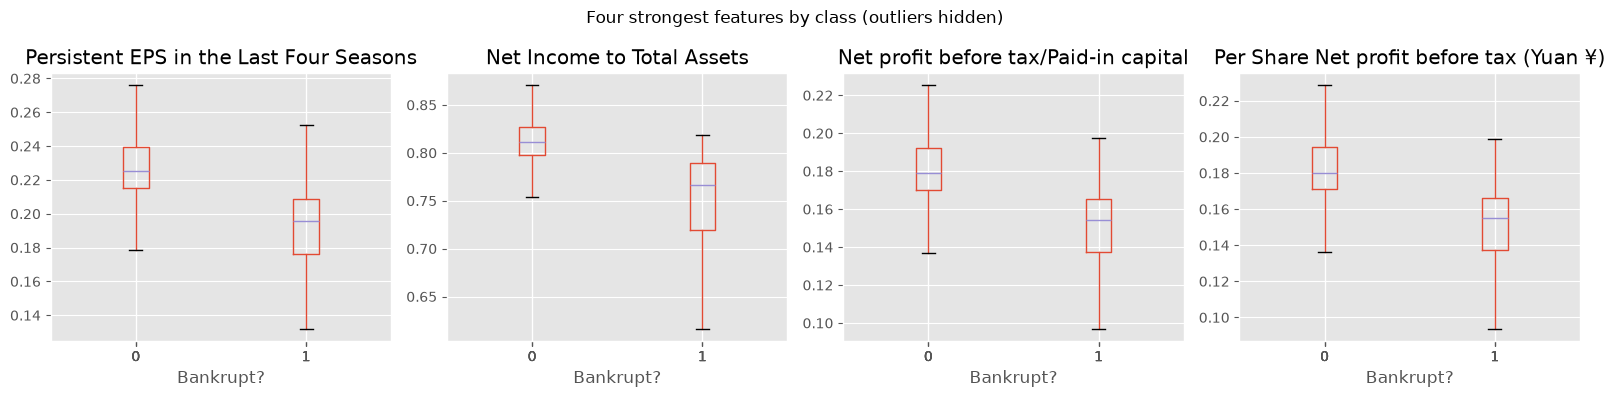

In [17]:
# Compare the distribution of the 4 strongest features between the two classes
df.boxplot(column=auc.index[:4].tolist(), by="Bankrupt?", layout=(1, 4), figsize=(16, 4), sharey=False, showfliers=False)
plt.suptitle("Four strongest features by class (outliers hidden)")
plt.tight_layout();

**Observation:** bankrupt firms are less profitable on all four ratios, but the two distributions overlap: no single ratio separates the classes on its own.

### 1.4 Train/test split

> **Decision:** hold out a stratified 20% test set (`random_state = SEED`). Stratification keeps the bankruptcy rate identical in both sets; the test set stays untouched until the final evaluation in Step 4.

In [18]:
# Hold out a stratified 20% test set
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)

In [19]:
# Compare the size, number of bankruptcies and bankruptcy rate of both sets
pd.concat({"train": y_train, "test": y_test}).groupby(level=0, sort=False).agg(["size", "sum", "mean"]).round(3)

,size,sum,mean
train,5455,176,0.032
test,1364,44,0.032


### 1.5 Step 1 takeaways

- **Imbalance.** Only 3.2% of firms went bankrupt, so accuracy is uninformative. Models are judged by their average misclassification cost ($C_{FN} = 10$, $C_{FP} = 1$) against the "never flag" baseline ($\approx 0.32$ per firm), and a firm is flagged when $P(Y = 1 \mid x) \geq 1/11$.
- **Redundancy.** 50 feature pairs have $|\rho| > 0.95$, involving half of the features: a strong case for variable selection (Step 2).
- **Signal.** Profitability ratios are the strongest individual predictors (AUC between 0.86 and 0.89), but the classes overlap, which calls for combining variables.
- **Scale artifacts.** 24 features contain values between $6 \times 10^5$ and $10^{10}$: harmless for the tree, to be handled for the linear selector in Step 2.
- **Data ready.** `Net Income Flag` is dropped (94 features left) and the data is split into 5,455 training firms (176 bankrupt) and 1,364 test firms (44 bankrupt), the latter locked until Step 4.

## 2. Variable Selection

### 2.1 Method

The outcome is binary, so the LASSO of Lecture 4 takes the form of an **L1-penalised logistic regression** with an unpenalised intercept:

$$\min_{b_0,\,\beta}\; -\frac{1}{n}\sum_{i=1}^{n}\Big[y_i \log p_i + (1-y_i)\log(1-p_i)\Big] + \lambda \lVert\beta\rVert_1, \qquad p_i = \frac{1}{1+e^{-(b_0 + x_i^\top\beta)}}.$$

In scikit-learn, the penalty is set through $C = 1/(n\lambda)$: a smaller $C$ means a stronger penalty and fewer selected variables. The LASSO only **chooses** the variables: the tree of Step 3 receives them with their raw values, so its split thresholds stay in the original ratio units.

> **Decision:** use the LASSO rather than forward selection (Lecture 3.2). A single parameter controls the number of variables, it copes with the strongly correlated ratios found in 1.3, and one fit takes under a second, so it can be refit inside every cross-validation fold of Step 3. Forward selection would need up to 94 model fits per added variable, repeated in every fold.

In [20]:
# Check whether the magnitude of the extreme values carries signal (training firms with Total Asset Growth Rate > 1)
extreme = X_train["Total Asset Growth Rate"] > 1
roc_auc_score(y_train[extreme], X_train.loc[extreme, "Total Asset Growth Rate"])

0.28163363014631826

**Observation:** among the 4,816 training firms whose `Total Asset Growth Rate` exceeds 1, the value alone reaches an AUC of 0.28, i.e. 0.72 in the reverse direction (lower values go with bankruptcy). The extreme values are not pure noise: their order carries signal and must be kept.

> **Decision:** feed the LASSO a rank-based quantile transform of the features (to a standard normal), fitted on training data only. It keeps the order of the values, and therefore the signal shown above, removes the magnitude problem and puts all features on the same scale, which a fair L1 penalty requires. The transform is not passed on to the tree.

> **Decision:** keep the intercept unpenalised, as in the course. scikit-learn's `liblinear` solver penalises it by default; `intercept_scaling=100` makes this penalty negligible.

> **Decision:** no class weights in the LASSO. It is a penalised maximum-likelihood fit whose role is to choose variables; the misclassification costs enter in Step 3, where the decision is made.

In [21]:
# Define the LASSO pipeline: rank-based quantile transform, then L1-penalised logistic regression
lasso = make_pipeline(QuantileTransformer(output_distribution="normal"),
                      LogisticRegression(l1_ratio=1, solver="liblinear", intercept_scaling=100, random_state=SEED))

### 2.2 Choice of the penalty

> **Decision:** choose $C$ by 5-fold stratified cross-validation on the training set, minimising the log-loss: a proper scoring rule for probabilities, and the classification counterpart of the validation MSE used in the course. The grid has 13 values of $C$ from $10^{-3}$ to $1$ on a log scale. The same folds are reused in Step 3.

In [22]:
# Define the 5-fold stratified cross-validation splitter (reused in Step 3)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

In [23]:
# Cross-validate the LASSO over the grid of C values and keep the one with the lowest log-loss
C_grid = np.logspace(-3, 0, 13)
lasso_cv = GridSearchCV(lasso, {"logisticregression__C": C_grid}, cv=cv, scoring="neg_log_loss", n_jobs=-1).fit(X_train, y_train)
best_C = lasso_cv.best_params_["logisticregression__C"]
print(f"Best C = {best_C:.3f} | CV log-loss = {-lasso_cv.best_score_:.4f}")

Best C = 0.178 | CV log-loss = 0.0855


In [24]:
# Count the variables selected for each value of C (refit on the full training set)
n_selected = [np.count_nonzero(lasso.set_params(logisticregression__C=c).fit(X_train, y_train)[-1].coef_) for c in C_grid]

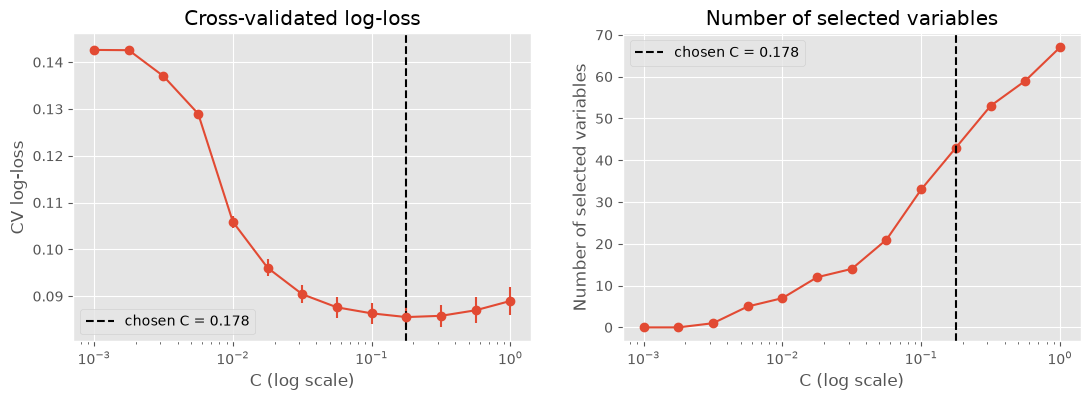

In [25]:
# Plot the CV log-loss (mean ± 1 standard error across folds) and the number of selected variables against C
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
ax1.errorbar(C_grid, -lasso_cv.cv_results_["mean_test_score"], yerr=lasso_cv.cv_results_["std_test_score"] / np.sqrt(5), marker="o")
ax1.set(xscale="log", xlabel="C (log scale)", ylabel="CV log-loss", title="Cross-validated log-loss")
ax2.plot(C_grid, n_selected, marker="o")
ax2.set(xscale="log", xlabel="C (log scale)", ylabel="Number of selected variables", title="Number of selected variables")
for ax in (ax1, ax2): ax.axvline(best_C, color="black", linestyle="--", label=f"chosen C = {best_C:.3f}"); ax.legend()

**Observation:** the CV log-loss falls from 0.143 with no variable to a minimum of 0.0855 at $C \approx 0.178$, which keeps 43 of the 94 variables, then rises again as the model starts to overfit. The curve is flat around the minimum: every $C$ between 0.056 (21 variables) and 0.562 (59 variables) is within one standard error (0.002) of it.

### 2.3 Selected variables

In [26]:
# List the variables selected at the chosen C with their coefficients, by decreasing magnitude
coefs = pd.Series(lasso_cv.best_estimator_[-1].coef_[0], index=X_train.columns)
selected = coefs[coefs != 0].sort_values(key=abs, ascending=False)
selected.round(3)

Total debt/Total net worth                                 0.819
ROA(B) before interest and depreciation after tax         -0.477
Retained Earnings to Total Assets                         -0.415
Interest-bearing debt interest rate                        0.350
Quick Ratio                                               -0.320
Working capitcal Turnover Rate                             0.314
Persistent EPS in the Last Four Seasons                   -0.311
Borrowing dependency                                       0.308
Inventory and accounts receivable/Net value               -0.295
Cash/Total Assets                                         -0.275
Total expense/Assets                                       0.266
Allocation rate per person                                 0.212
Accounts Receivable Turnover                              -0.180
Operating Profit Per Share (Yuan ¥)                        0.172
Revenue per person                                         0.169
Fixed Assets Turnover Fre

**Observation:** the 43 selected variables cover leverage (`Total debt/Total net worth`, `Borrowing dependency`), profitability (`ROA(B)`, `Retained Earnings to Total Assets`, `Persistent EPS`), liquidity (`Quick Ratio`, `Cash/Total Assets`) and activity ratios. The coefficients are on the quantile-normal scale, so their magnitudes are comparable: a positive sign means that a higher ratio raises the predicted bankruptcy risk (more debt), a negative sign that it lowers it (more profit). As Lectures 3–4 warn, a non-zero coefficient is not a causal effect, and the choice between near-duplicate ratios is partly arbitrary: the LASSO even keeps both `Current Liabilities/Liability` and its practically identical twin `Current Liability to Liability`, with tiny coefficients.

### 2.4 Selection stability

> **Decision:** measure stability on 100 stratified bootstrap resamples of the training set (Lecture 4), keeping $C$ fixed and refitting the whole procedure, quantile transform included. The selection frequencies are descriptive: they do not change the selected set.

In [27]:
# Refit the LASSO (chosen C) on 100 bootstrap resamples and record how often each variable is selected
lasso.set_params(logisticregression__C=best_C)
boot_coefs = [lasso.fit(*resample(X_train, y_train, stratify=y_train, random_state=b))[-1].coef_[0] for b in range(100)]
freq = pd.Series(np.mean(np.array(boot_coefs) != 0, axis=0), index=X_train.columns).sort_values(ascending=False)

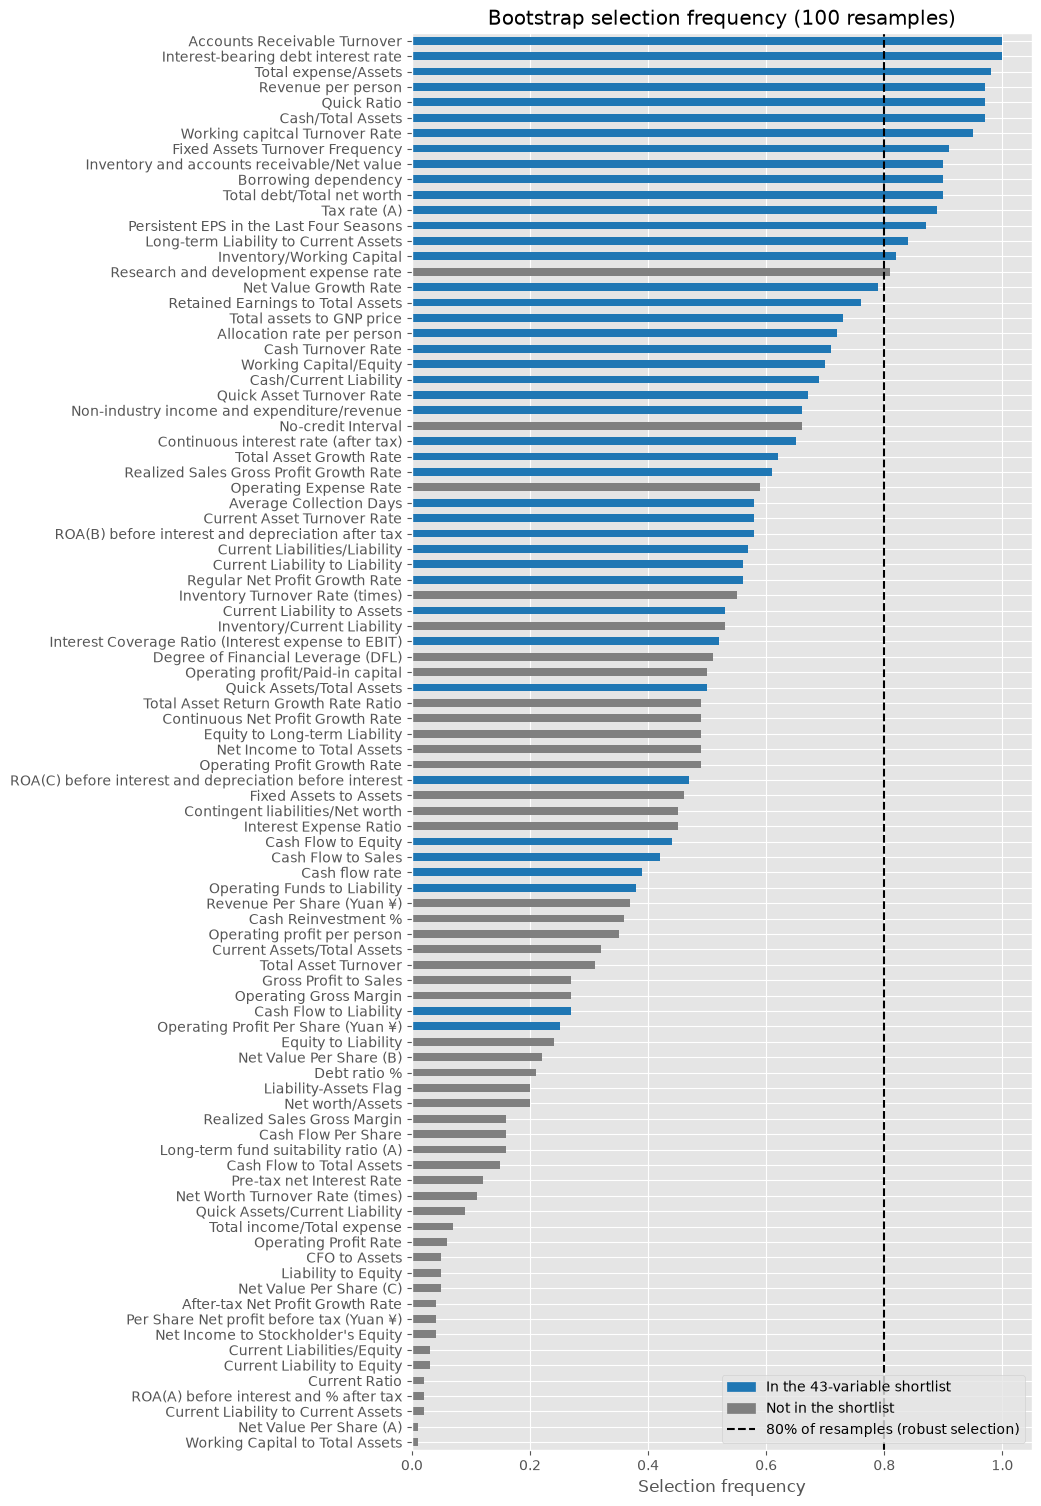

In [28]:
# Plot the selection frequency of every variable selected at least once, coloured by membership of the 43-variable shortlist (2.3)
shown = freq[freq > 0].iloc[::-1]
ax = shown.plot.barh(figsize=(8, 0.2 * len(shown)), color=np.where(shown.index.isin(selected.index), "tab:blue", "tab:gray"),
                     title="Bootstrap selection frequency (100 resamples)")
line = ax.axvline(0.8, color="black", linestyle="--", label="80% of resamples (robust selection)")
ax.set_xlabel("Selection frequency")
ax.legend(handles=[Patch(color="tab:blue", label="In the 43-variable shortlist"), Patch(color="tab:gray", label="Not in the shortlist"), line], loc="lower right");

This plot answers the following question: 

**If our training data had been slightly different, to what extent would the LASSO still pick this variable ?**

Blue means the variable is selected, grey means it is not.

- Long and Blue means the variable is on the list of predictive variables that are picked almost everytime, it is a robust choice.

- Short and Blue means the variable is in our list only through the luck of this particular sample.

- Long and grey means it is not on our list yet it is picked in most resamples, its absence is fragile.

- Short and grey means the variable is consistently left out, we are confident that it is not important for the LASSO.

**Observation:** only 15 of the 43 selected variables are kept in at least 80% of the resamples (right of the dashed line); the median frequency is 0.69 and the lowest 0.25. Conversely, some variables left out on the full training set are often selected, e.g. `Research and development expense rate` (81%). Correlated ratios swap places from one resample to the next: the selected set is a useful predictive shortlist, not a unique list of "true" predictors (Lecture 4).

> **Decision:** hand the selection over to Step 3 as a `SelectFromModel` object wrapping the LASSO at the chosen $C$. It sits in front of the tree and is refit inside every cross-validation fold. Step 3 also compares this fixed $C$ with tuning $C$ together with the tree on the decision cost, using the same folds; the joint version is preferred only if its CV cost is lower by more than one standard error.

In [29]:
# Wrap the LASSO (chosen C) as a selector that passes the raw values of the selected variables on to the tree
selector = SelectFromModel(lasso.set_params(logisticregression__C=best_C),
                           importance_getter="named_steps.logisticregression.coef_",
                           threshold=1e-5)  # keep the variables with a non-zero coefficient

In [30]:
# Check that the selector, fitted on the full training set, keeps exactly the variables listed in 2.3
set(selector.fit(X_train, y_train).get_feature_names_out()) == set(selected.index)

True

### 2.5 Step 2 takeaways

- **Method.** L1-penalised logistic regression on quantile-transformed features, with an unpenalised intercept. The tree receives the raw values of the selected variables.
- **Penalty.** $C \approx 0.178$, chosen by 5-fold CV log-loss, keeps **43 of the 94 variables** (CV log-loss 0.0855 against 0.143 with no variable). The curve is flat between 21 and 59 variables.
- **Content.** Leverage, profitability, liquidity and activity ratios. The signs of the leading variables match intuition: more debt raises the risk, more profit and liquidity lower it.
- **Stability.** Moderate: 15 variables are selected in at least 80% of the resamples, and correlated ratios are interchangeable.
- **Hand-off.** `selector` (the LASSO at the chosen $C$, wrapped in `SelectFromModel`) and `cv` (the 5 folds) are ready for Step 3, where the selector is refit inside every fold and compared with tuning $C$ jointly with the tree.

## 3. Model Selection and Decision Tree Tuning

### 3.1 Decision rule and metric

Each leaf of a tree holds training firms; its share of bankrupt firms estimates $\hat\eta(x) = P(Y = 1 \mid x)$ for every firm that reaches it (Lecture 3). The decision then follows the Bayes rule of 1.1: flag the firm when $\hat\eta(x) \geq 1/11$. Every model is wrapped in a `FixedThresholdClassifier`, so that its predictions are directly the cost-optimal decisions, and models are compared on the average cost per firm, i.e. the empirical risk under the loss table:

$$\hat R_n = \frac{1}{n}\sum_{i=1}^{n} L\big(\hat a_i, y_i\big) = \frac{C_{FN}\cdot\text{FN} + C_{FP}\cdot\text{FP}}{n}.$$

> **Decision:** the costs enter through the decision threshold, not through class weights: the threshold keeps the reading of leaves as probability estimates and lets Step 4 test other cost ratios by changing only the threshold, without retraining.

In [31]:
# Define the evaluation metric: average misclassification cost per firm (empirical risk under the loss table, costs of 1.1 by default)
def avg_cost(y_true, y_pred, c_fn=C_FN, c_fp=C_FP):
    return np.mean(c_fn * ((y_true == 1) & (y_pred == 0)) + c_fp * ((y_true == 0) & (y_pred == 1)))

In [32]:
# Turn the average cost into a scikit-learn scorer (lower is better)
cost_scorer = make_scorer(avg_cost, greater_is_better=False)

### 3.2 Candidates and tuning grid

> **Decision:** tune `max_depth` $\in \{2, 3, 4, 5, 6, 8, \text{no limit}\}$ and `min_samples_leaf` $\in \{1, 10, 20, 40, 80, 120, 160, 200\}$, with the Gini criterion. Leaf shares are only reliable probabilities in large enough leaves (Lecture 3): with a 3.2% bankruptcy rate, a leaf of 120 firms holds about 4 bankruptcies on average.

> **Decision:** compare four candidates on the same 5 folds, with the LASSO refit inside every training fold:
> - **M0**: the "never flag" baseline;
> - **M1**: a tree on all 94 features;
> - **M2**: the Step 2 selector with $C$ fixed at 0.178, followed by a tree;
> - **M3**: the same pipeline with $C$ tuned jointly with the tree, over the 7 grid values from 0.01 to 0.316, which include M2's value.

> **Decision:** M2, the course protocol, is the reference. An alternative replaces it only if its CV cost is lower by more than one standard error. Since all candidates share the same 5 folds, the comparison is paired: the standard error is that of the per-fold gains over M2 (their standard deviation divided by $\sqrt{5}$). This rule was fixed in Step 2, before these results were seen.

In [33]:
# Define the tree hyperparameter grid: maximum depth and minimum number of firms per leaf
tree_grid = {"max_depth": [2, 3, 4, 5, 6, 8, None], "min_samples_leaf": [1, 10, 20, 40, 80, 120, 160, 200]}

### 3.3 Cross-validated tuning

In [34]:
# M0: cross-validate the "never flag" baseline
m0_costs = -cross_val_score(DummyClassifier(strategy="most_frequent"), X_train, y_train, cv=cv, scoring=cost_scorer)
print(f"M0 never flag: CV cost = {m0_costs.mean():.4f}")

M0 never flag: CV cost = 0.3226


In [35]:
# M1: tune a thresholded tree on all 94 features
m1 = GridSearchCV(FixedThresholdClassifier(DecisionTreeClassifier(random_state=SEED), threshold=THRESHOLD),
                  {f"estimator__{k}": v for k, v in tree_grid.items()}, cv=cv, scoring=cost_scorer, n_jobs=-1).fit(X_train, y_train)
print(f"M1 all features: CV cost = {-m1.best_score_:.4f} | {m1.best_params_}")

M1 all features: CV cost = 0.1630 | {'estimator__max_depth': 4, 'estimator__min_samples_leaf': 120}


In [36]:
# M2: tune a thresholded pipeline (LASSO selector with C fixed at its Step 2 value, then tree)
pipe = FixedThresholdClassifier(Pipeline([("select", selector), ("tree", DecisionTreeClassifier(random_state=SEED))]), threshold=THRESHOLD)
m2_grid = {"estimator__select__estimator__logisticregression__C": [best_C], **{f"estimator__tree__{k}": v for k, v in tree_grid.items()}}
m2 = GridSearchCV(pipe, m2_grid, cv=cv, scoring=cost_scorer, n_jobs=-1, return_train_score=True).fit(X_train, y_train)
print(f"M2 LASSO, C fixed: CV cost = {-m2.best_score_:.4f} | {m2.best_params_}")

M2 LASSO, C fixed: CV cost = 0.1512 | {'estimator__select__estimator__logisticregression__C': np.float64(0.1778279410038923), 'estimator__tree__max_depth': 4, 'estimator__tree__min_samples_leaf': 120}


In [37]:
# M3: same pipeline, with C tuned jointly with the tree over the Step 2 grid values from 0.01 to 0.316
m3_grid = {**m2_grid, "estimator__select__estimator__logisticregression__C": C_grid[4:11]}
m3 = GridSearchCV(pipe, m3_grid, cv=cv, scoring=cost_scorer, n_jobs=-1).fit(X_train, y_train)
print(f"M3 LASSO, C joint: CV cost = {-m3.best_score_:.4f} | {m3.best_params_}")

M3 LASSO, C joint: CV cost = 0.1483 | {'estimator__select__estimator__logisticregression__C': np.float64(0.01), 'estimator__tree__max_depth': 3, 'estimator__tree__min_samples_leaf': 10}


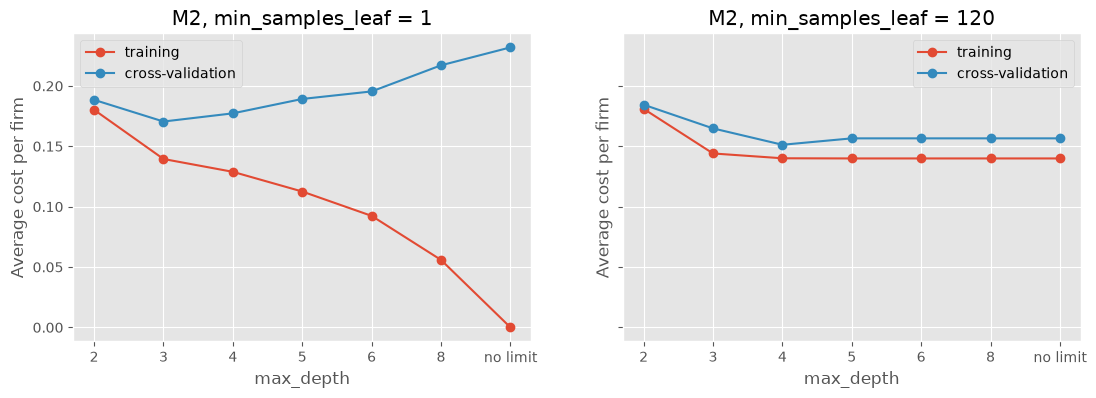

In [38]:
# Plot the M2 validation curve: training and CV cost against depth, for leaves of 1 firm and for the chosen leaf size
res = pd.DataFrame(m2.cv_results_)
best_leaf = m2.best_params_["estimator__tree__min_samples_leaf"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, leaf in zip(axes, [1, best_leaf]):
    r = res[res["param_estimator__tree__min_samples_leaf"] == leaf]
    depth = r["param_estimator__tree__max_depth"].fillna("no limit").astype(str)
    ax.plot(depth, -r["mean_train_score"], marker="o", label="training")
    ax.plot(depth, -r["mean_test_score"], marker="o", label="cross-validation")
    ax.set(title=f"M2, min_samples_leaf = {leaf}", xlabel="max_depth", ylabel="Average cost per firm")
    ax.legend()

**Observation:** with leaves of a single firm (left), the training cost falls to 0 as the tree deepens while the CV cost rises from 0.17 to 0.23: the tree memorises the training firms and overfits (Lecture 2). With leaves of at least 120 firms (right), the training–CV gap stays small and depth 4 gives the lowest CV cost (0.151); from depth 5 on, the curves are flat because the leaf size, not the depth, stops the growth.

### 3.4 Model comparison

In [39]:
# Summarise the four candidates: CV cost, its standard error across folds, best parameters and number of variables
def summary(gs):
    params = {k.split("__")[-1]: v for k, v in gs.best_params_.items()}
    return {"CV cost": -gs.best_score_, "SE": gs.cv_results_["std_test_score"][gs.best_index_] / np.sqrt(5), **params}
comparison = pd.DataFrame.from_dict({"M0 never flag": {"CV cost": m0_costs.mean(), "SE": m0_costs.std() / np.sqrt(5)},
                                     "M1 all features": summary(m1), "M2 LASSO, C fixed": summary(m2), "M3 LASSO, C joint": summary(m3)}, orient="index")
comparison["variables"] = [0, X_train.shape[1]] + [gs.best_estimator_.estimator_["select"].get_support().sum() for gs in (m2, m3)]
comparison.convert_dtypes().round(4)

,CV cost,SE,max_depth,min_samples_leaf,C,variables
M0 never flag,0.3226,0.0016,<NA>,<NA>,<NA>,0
M1 all features,0.163,0.009,4,120,<NA>,94
"M2 LASSO, C fixed",0.1512,0.0077,4,120,0.1778,43
"M3 LASSO, C joint",0.1483,0.0087,3,10,0.01,7


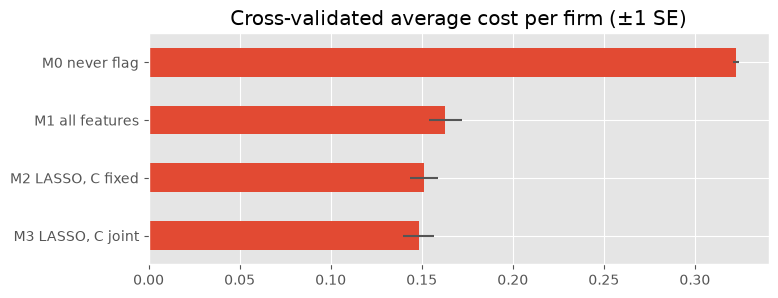

In [40]:
# Plot the CV cost of the four candidates with ±1 standard error bars
comparison["CV cost"].plot.barh(xerr=comparison["SE"], figsize=(8, 3), title="Cross-validated average cost per firm (±1 SE)").invert_yaxis()

In [41]:
# Collect the cost of each candidate on each of the 5 folds (best configuration of each grid search)
fold_costs = pd.DataFrame({"M0 never flag": m0_costs, **{name: [-gs.cv_results_[f"split{k}_test_score"][gs.best_index_] for k in range(5)]
                                                         for name, gs in [("M1 all features", m1), ("M2 LASSO, C fixed", m2), ("M3 LASSO, C joint", m3)]}})

In [42]:
# Apply the selection rule on paired gains: an alternative replaces M2 only if its mean per-fold gain over M2 exceeds the gain's standard error
gains = fold_costs.rsub(fold_costs["M2 LASSO, C fixed"], axis=0)  # positive = cheaper than M2 on that fold
rule = pd.DataFrame({"mean gain over M2": gains.mean(), "paired SE": gains.std() / np.sqrt(5), "folds cheaper than M2": (gains > 0).sum()})
rule["replaces M2"] = rule["mean gain over M2"] > rule["paired SE"]
rule.round(4)

,mean gain over M2,paired SE,folds cheaper than M2,replaces M2
M0 never flag,-0.1714,0.0087,0,False
M1 all features,-0.0117,0.0047,0,False
"M2 LASSO, C fixed",0.0000,0.0000,0,False
"M3 LASSO, C joint",0.0029,0.0069,3,False


> **Decision:** keep M2 as the final model, since no alternative beats it by more than one paired standard error. M1, on all 94 features, is worse by $0.012 \pm 0.005$, and M2 is cheaper or tied on every fold: the variable selection helps. M3 reaches a slightly lower cost with a much sparser selection ($C = 0.01$, 7 variables), but its gain ($0.003 \pm 0.007$, cheaper on 3 folds and dearer on 2) is within the noise.

### 3.5 Final model

In [43]:
# Freeze the final model: M2 refitted on the full training set with its best parameters
final_model = m2.best_estimator_

In [44]:
# Describe the final model: variables kept by the LASSO, variables actually used by the tree, size of the tree
selected_vars = final_model.estimator_["select"].get_feature_names_out()
final_tree = final_model.estimator_["tree"]
used_vars = selected_vars[np.unique(final_tree.tree_.feature[final_tree.tree_.feature >= 0])]
print(f"{len(selected_vars)} variables selected | {len(used_vars)} used by the tree | depth {final_tree.get_depth()} | {final_tree.get_n_leaves()} leaves")
list(used_vars)

43 variables selected | 8 used by the tree | depth 4 | 9 leaves


['Continuous interest rate (after tax)',
 'Interest-bearing debt interest rate',
 'Persistent EPS in the Last Four Seasons',
 'Net Value Growth Rate',
 'Borrowing dependency',
 'Inventory/Working Capital',
 'Quick Asset Turnover Rate',
 'Interest Coverage Ratio (Interest expense to EBIT)']

**Observation:** the final tree has depth 4 and 9 leaves, and uses only 8 of the 43 selected variables: profitability (`Persistent EPS in the Last Four Seasons`, and `Continuous interest rate (after tax)`, part of the profitability block of 1.3), debt and its cost (`Borrowing dependency`, `Interest-bearing debt interest rate`, `Interest Coverage Ratio`), growth (`Net Value Growth Rate`) and activity (`Inventory/Working Capital`, `Quick Asset Turnover Rate`). The tree performs a second, finer selection on top of the LASSO.

### 3.6 Benchmark: the price of interpretability

> **Decision:** measure what the readability of a single tree costs, with a benchmark M4: a random forest of 300 trees on the LASSO-selected variables, cross-validated on the same folds, tuning only its leaf size. A forest is the course's voting idea (Lecture 2): many trees vote, which gives finer probabilities than 9 leaves. M4 is a benchmark, not a candidate: the brief asks for a decision-tree classifier, and the decision memo relies on reading the tree's rules. It is not scored on the test set.

In [45]:
# M4 (benchmark): tune a thresholded pipeline (LASSO selector with C fixed, then a random forest of 300 trees)
forest = FixedThresholdClassifier(Pipeline([("select", selector), ("forest", RandomForestClassifier(n_estimators=300, random_state=SEED))]), threshold=THRESHOLD)
m4_grid = {"estimator__select__estimator__logisticregression__C": [best_C], "estimator__forest__min_samples_leaf": [1, 5, 10, 20, 40]}
m4 = GridSearchCV(forest, m4_grid, cv=cv, scoring=cost_scorer, n_jobs=-1).fit(X_train, y_train)
print(f"M4 LASSO + forest: CV cost = {-m4.best_score_:.4f} | {m4.best_params_}")

M4 LASSO + forest: CV cost = 0.1364 | {'estimator__forest__min_samples_leaf': 10, 'estimator__select__estimator__logisticregression__C': np.float64(0.1778279410038923)}


In [46]:
# Compare M4 with M2 on paired per-fold costs (positive gain = M4 cheaper)
m4_gain = fold_costs["M2 LASSO, C fixed"] - [-m4.cv_results_[f"split{k}_test_score"][m4.best_index_] for k in range(5)]
print(f"M4 gain over M2: {m4_gain.mean():.4f} ± {m4_gain.std() / np.sqrt(5):.4f} | cheaper on {(m4_gain > 0).sum()} of 5 folds")

M4 gain over M2: 0.0148 ± 0.0069 | cheaper on 5 of 5 folds


**Observation:** the forest costs 0.136 per firm against 0.151 for M2, a gain of $0.015 \pm 0.007$, cheaper on all 5 folds: about 10% of the cost is the price of a single readable tree. M2 remains the final model.

### 3.7 Step 3 takeaways

- **Decision rule.** Leaf shares estimate the bankruptcy probability, and a firm is flagged when it reaches $1/11$. All models are tuned and compared on the average cost per firm, over the same 5 folds.
- **Trees halve the baseline cost.** From 0.323 per firm ("never flag") to 0.15–0.16.
- **Selection helps.** The LASSO + tree (M2, 0.151) beats the tree on all 94 features (M1, 0.163) by $0.012 \pm 0.005$ (paired across folds), and is cheaper or tied on every fold.
- **Joint tuning does not help significantly.** M3 (0.148) is within noise of M2 (gain $0.003 \pm 0.007$), but it shows that a 7-variable selection works about as well, a point for the discussion.
- **Large leaves matter.** Leaves of at least 120 firms keep the probability estimates reliable and prevent overfitting; with leaves of a single firm, the CV cost rises to 0.23.
- **Price of interpretability.** A random forest on the same selected variables (M4, benchmark only) costs 0.136 per firm, $0.015 \pm 0.007$ less than M2, on every fold: the single tree gives up about 10% of the cost for readable rules.
- **Final model, frozen for Step 4.** M2: the LASSO ($C \approx 0.178$, 43 variables) followed by a depth-4 tree with leaves of at least 120 firms, which has 9 leaves and actually uses 8 variables.

## 4. Evaluation of the Final Model

### 4.1 Test-set performance

> **Decision:** the test set is used once, here, to score the frozen final model (M2) and the "never flag" baseline only. The rejected candidates M1 and M3, and the benchmark M4, are not scored on it: choosing again on test results would make the test score part of model selection (Lecture 2).

> **Decision:** report the average cost per firm (primary metric), recall, precision, the number of flagged firms and the confusion matrix. Accuracy is shown only to illustrate why it was rejected in 1.1.

In [47]:
# Define a helper that computes the test metrics of a set of decisions (cost under a given cost ratio)
def test_metrics(y_true, y_pred, c_fn=C_FN):
    return {"avg cost": avg_cost(y_true, y_pred, c_fn), "recall": recall_score(y_true, y_pred),
            "precision": precision_score(y_true, y_pred, zero_division=np.nan), "accuracy": accuracy_score(y_true, y_pred),
            "flagged firms": int(y_pred.sum())}

In [48]:
# Predict the decisions of the final model and of the baseline (which flags nobody) on the test set
y_pred = final_model.predict(X_test)
y_base = np.zeros(len(y_test), dtype=int)

In [49]:
# Compare the final model with the baseline on the test set
pd.DataFrame.from_dict({"Final model (M2)": test_metrics(y_test, y_pred), "Baseline (never flag)": test_metrics(y_test, y_base)}, orient="index").round(4)

,avg cost,recall,precision,accuracy,flagged firms
Final model (M2),0.1789,0.7273,0.2051,0.9003,156
Baseline (never flag),0.3226,0.0000,NaN,0.9677,0


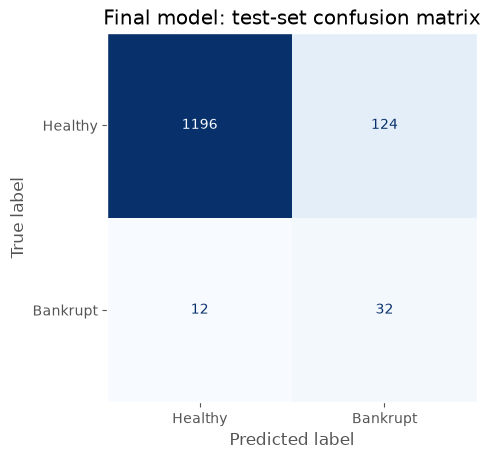

In [50]:
# Plot the confusion matrix of the final model on the test set
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["Healthy", "Bankrupt"], cmap="Blues", colorbar=False)
plt.title("Final model: test-set confusion matrix")
plt.grid(False);

**Observation:** on the 1,364 test firms, the final model costs 0.179 per firm against 0.323 for "never flag", a 45% reduction. It catches 32 of the 44 bankruptcies (recall 73%) at the price of 124 false alarms (precision 21%): 156 firms are flagged, about 1 in 9. Its accuracy (90%) is lower than the baseline's (97%), which confirms that accuracy would have rewarded the useless rule. The test cost is higher than the CV estimate (0.151), a gap examined below.

### 4.2 Uncertainty of the test estimate

> **Decision:** measure the uncertainty of the test costs with a 95% percentile bootstrap: 1,000 resamples of the 1,364 test firms, with the predictions fixed, for the model, the baseline and their paired difference. The resamples are not stratified, so the number of bankruptcies varies as it would in a new sample of firms. Lecture 2's Hoeffding bound, computed below for reference, is valid but too wide to be informative here.

In [51]:
# Compute Lecture 2's Hoeffding half-width for a test cost bounded in [0, C_FN], at 95% confidence
C_FN * np.sqrt(np.log(2 / 0.05) / (2 * len(y_test)))

np.float64(0.36772660209700225)

In [52]:
# Recompute the test costs of the model and of the baseline on 1,000 bootstrap resamples of the test firms
boot = [resample(np.arange(len(y_test)), random_state=b) for b in range(1000)]
boot_costs = pd.DataFrame([{"Final model": avg_cost(y_test.values[i], y_pred[i]), "Baseline": avg_cost(y_test.values[i], y_base[i])} for i in boot])
boot_costs["Difference (model − baseline)"] = boot_costs["Final model"] - boot_costs["Baseline"]

In [53]:
# Report the 95% percentile intervals of the bootstrap costs
boot_costs.quantile([0.025, 0.975]).T.round(4)

,0.025,0.975
Final model,0.1342,0.2332
Baseline,0.2346,0.4181
Difference (model − baseline),-0.2280,-0.0652


**Observation:** the Hoeffding half-width ($\pm 0.37$) exceeds the gap between the two rules, so it cannot separate them. The bootstrap gives a 95% interval of $[0.134, 0.233]$ for the model's cost and $[0.235, 0.418]$ for the baseline's, and the paired difference lies in $[-0.228, -0.065]$, entirely below 0: the model's advantage is not an artefact of this test set. The CV estimate (0.151) lies inside the model's interval, and the gap is expected: with only 44 test bankruptcies the test cost is noisy, and the CV cost of the chosen configuration, the best of 56, is slightly optimistic.

### 4.3 Sensitivity to the cost ratio

> **Decision:** re-evaluate the final model for cost ratios $C_{FN}/C_{FP} \in \{5, 10, 20\}$. For each ratio $r$, the Bayes threshold becomes $1/(1+r)$; the tree is not retrained, and the baseline is evaluated under the same ratio.

In [54]:
# Compute the test-set bankruptcy probabilities of the final model once (the shares of the leaves reached)
p_test = final_model.predict_proba(X_test)[:, 1]

In [55]:
# Evaluate the final model and the baseline under cost ratios 5, 10 and 20, with the matching Bayes threshold 1/(1+r)
pd.DataFrame.from_dict({r: {"threshold": 1 / (1 + r), **test_metrics(y_test, (p_test >= 1 / (1 + r)).astype(int), c_fn=r),
                  "baseline cost": avg_cost(y_test, y_base, c_fn=r)} for r in (5, 10, 20)}, orient="index").rename_axis("cost ratio").round(4)

,threshold,avg cost,recall,precision,accuracy,flagged firms,baseline cost
cost ratio,,,,,,,
5,0.1667,0.1056,0.5455,0.3529,0.9531,68,0.1613
10,0.0909,0.1789,0.7273,0.2051,0.9003,156,0.3226
20,0.0476,0.2669,0.7273,0.2051,0.9003,156,0.6452


**Observation:** the model beats the baseline under all three cost ratios, cutting its cost by 35% at $r = 5$, 45% at $r = 10$ and 59% at $r = 20$. Ratios 10 and 20 give exactly the same decisions (156 flagged firms); at ratio 5 the threshold rises to $1/6$ and only 68 firms are flagged, with a recall of 55%.

> **Decision:** complete the sensitivity analysis with each leaf's switching ratio $r^* = (1-\hat\eta)/\hat\eta$, computed from its training share $\hat\eta$: since $\hat\eta \geq 1/(1+r) \iff r \geq r^*$, it is the cost ratio from which the leaf is flagged. It shows exactly where the decisions change (Lecture 1).

In [56]:
# Describe each leaf of the final tree: training firms, bankruptcy share, decision at 1/11 and switching ratio r*
t = final_tree.tree_
leaves = np.where(t.children_left == -1)[0]
leaf_table = pd.DataFrame({"training firms": t.n_node_samples[leaves], "bankruptcy share": t.value[leaves, 0, 1]}, index=pd.Index(leaves, name="node"))
leaf_table["flagged at 1/11"] = leaf_table["bankruptcy share"] >= THRESHOLD
leaf_table["switching ratio r*"] = (1 - leaf_table["bankruptcy share"]) / leaf_table["bankruptcy share"]
leaf_table.sort_values("bankruptcy share", ascending=False).round(3)

,training firms,bankruptcy share,flagged at 1/11,switching ratio r*
node,,,,
1,150,0.420,True,1.381
13,121,0.397,True,1.521
12,146,0.116,True,7.588
6,129,0.093,True,9.750
15,129,0.093,True,9.750
8,155,0.039,False,24.833
5,122,0.016,False,60.000
16,264,0.015,False,65.000
9,4239,0.003,False,352.250


**Observation:** two leaves (nodes 1 and 13, bankruptcy shares of 42% and 40%) are flagged for any cost ratio above 1.5: robust decisions. Node 12 (12%) switches at 7.6, and nodes 6 and 15 (9.3%) at 9.75, just below our assumed ratio of 10: these two leaves, 258 training firms, are flagged only narrowly. No leaf switches between 9.75 and 24.8, which explains why ratios 10 and 20 give identical decisions. The leaf holding 78% of the training firms (node 9) has a bankruptcy share of 0.3% and would only be flagged above a ratio of 352.

### 4.4 Interpretation of the final tree

> **Decision:** draw the tree with its node ids and read the decisions from the leaf table above. `plot_tree` would label each leaf with its majority class, which is "healthy" in all 9 leaves, whereas the decision depends on the 1/11 threshold; class labels and colours are therefore left out.

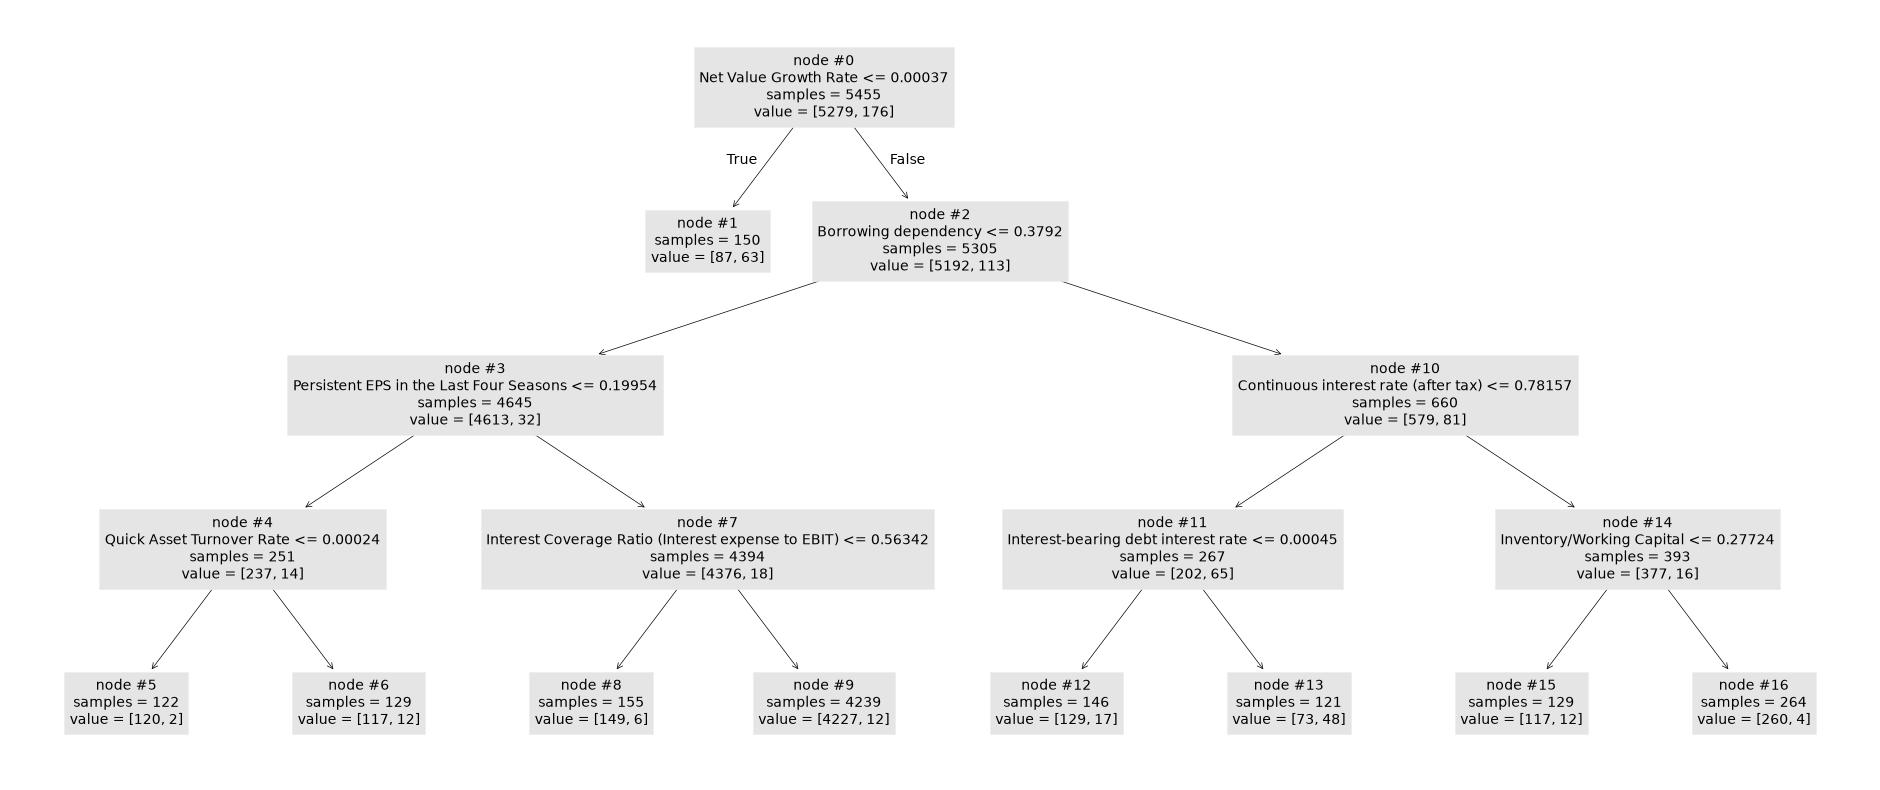

In [57]:
# Plot the final tree: split rules in raw ratio units, node ids, training firms and class counts [healthy, bankrupt]
plt.figure(figsize=(24, 10))
plot_tree(final_tree, feature_names=selected_vars, node_ids=True, impurity=False, precision=5, fontsize=10);

**Observation:** reading the flagged leaves from the leaf table, the tree raises an alarm in three situations:
1. the 2.7% of firms with the lowest net value growth (node 1, 42% bankrupt);
2. heavy reliance on borrowing combined with weak profitability, especially when the debt is expensive (node 13, 40%; node 12, 12%);
3. two narrower pockets around 9%: low earnings per share with a higher quick-asset turnover rate (node 6), and heavily indebted but profitable firms with low inventory relative to working capital (node 15).

Conversely, firms with moderate borrowing, EPS above 0.20 and an interest coverage ratio above 0.56 (node 9, 78% of the training firms) almost never go bankrupt (0.3%). These are predictive associations, not causal effects.

### 4.5 Recommendation and limitations

**Recommendation.** Use the final model to screen firms: flag every firm that reaches one of the five flagged leaves, i.e. whose estimated bankruptcy probability is at least $1/11$, for credit restriction or closer review.

1. **Action and information.** Flag or do not flag a firm, using 8 financial ratios read by a depth-4 tree; the LASSO narrowed the 94 ratios down to 43 and the tree uses 8 of them.
2. **Assumptions.** A missed bankruptcy costs ten times a false alarm ($C_{FN} = 10$, $C_{FP} = 1$), and the leaf shares of 5,455 training firms are taken as bankruptcy probabilities.
3. **Comparison with the alternative.** On 1,364 unseen firms, the model costs 0.179 per firm against 0.323 without screening (95% interval of the gain: 0.065 to 0.228). It flags 1 firm in 9 and catches 32 of the 44 bankruptcies, at the price of 124 false alarms. A random forest on the same variables would lower the cross-validated cost by about 10% (3.6), but without the readable rules this memo relies on.
4. **Conditions that would change the choice.** If a missed bankruptcy cost less than about 9.75 false alarms, two leaves would no longer be flagged, and below 7.6 a third. The decisions are unchanged for any ratio between 9.75 and 24.8.

**Limitations.**
- **No time dimension.** Firms are pooled over 1999–2009 without a year, so the evaluation is a random split, not a forecast of future years; economic conditions and accounting rules may shift (Lecture 2: a split does not repair distribution shift).
- **Possibly repeated firms.** The rows may include several years of the same firm. If so, the random split can place the same firm in both training and test, and the test cost (0.179) may be optimistic for genuinely new firms (Lecture 2: a split does not repair dependence). Without a firm identifier, this can be neither checked nor corrected.
- **Stipulated costs.** The 10 : 1 ratio is an assumption, and the decisions of two leaves depend on it being at least 9.75.
- **Few bankruptcies.** With 176 bankruptcies in training and 44 in test, CV estimates have standard errors of about 0.008, the test interval is wide, and leaf shares rest on 2 to 63 bankruptcies; in particular, nodes 6 and 15 are flagged with a share of 0.093, only 0.002 above the threshold, while that share's standard error is about $\sqrt{0.093 \times 0.907 / 129} \approx 0.026$: their decision lies within estimation noise.
- **Model comparison without nested CV.** M2 and M3 were compared on the same folds used to tune them; the selection rule limits this optimism but does not remove it.
- **Unstable variable list.** Only 15 of the 43 LASSO variables are selected in at least 80% of bootstrap resamples, and a 7-variable selection (M3) works about as well: the 8 ratios used by the tree form a good predictive set, not the unique causes of bankruptcy.
- **Data quality.** 24 ratios contain extreme values that look like encoding artefacts, and 3 of the 8 ratios used by the tree are among them (`Net Value Growth Rate`, `Quick Asset Turnover Rate`, `Interest-bearing debt interest rate`). The rank-based LASSO input and the tree's order-based splits limit their impact.
- **Deployment.** Before use, the frozen procedure should be refit on all 6,819 firms and validated on more recent data.